# Edafologia en Zonas Agricolas


In [1]:
from config.paths import datapaths
import geopandas as gpd



file1 = gpd.read_file(datapaths['raw']['INEGI'] / "702825266707_s"/"perfiles_suelos_shp"/"perfiles_serieii.shp")
file1.shape


(16820, 68)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

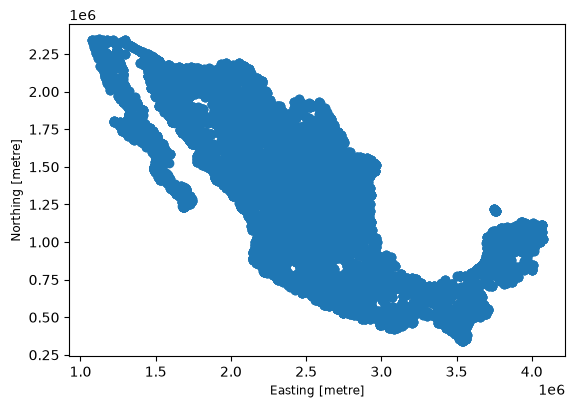

In [2]:
file1.plot()

In [3]:
file1.columns

Index(['ID_PERFIL', 'COORD_X', 'COORD_Y', 'ZONA', 'IDHOJA', 'FECHA',
       'CLAVE_WRB', 'GPO_SUELO', 'CALIF_PRIM', 'CALIF_SEC', 'F_RÚDICA',
       'ALTITUD', 'PRECIP', 'TEMP', 'GEOLOGÍA', 'VEGETACIÓN', 'PENDIENTE',
       'RELIEVE', 'PEDREG', 'AFLORAM', 'LIM_SUP', 'LIM_INF', 'NOMEN_HTE',
       'HORIZONTE', 'PROP_MAT', 'HCL', 'EST_FORMA', 'EST_TAM', 'EST_DES',
       'COL_CAMPO', 'CONS_SECO', 'CONS_HUM', 'ADHE', 'PLAS', 'PELÍCULAS',
       'FACETAS', 'GRIETAS', 'GRAVAS', 'GUIJARROS', 'PIEDRAS', 'CONCRECIÓN',
       'NÓDULOS', 'MANCHAS', 'RAÍCES', 'DREN_EXT', 'DREN_INT', 'R', 'L', 'A',
       'CLAS_TEXT', 'COL_SECO_L', 'COL_HUM_L', 'CE', 'PH', 'CO', 'CIC', 'SB',
       'SNA', 'K', 'CA', 'NA', 'MG', 'CACO3', 'CASO4', 'ID_FOTO', 'CAL_POS',
       'OID', 'geometry'],
      dtype='str')

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

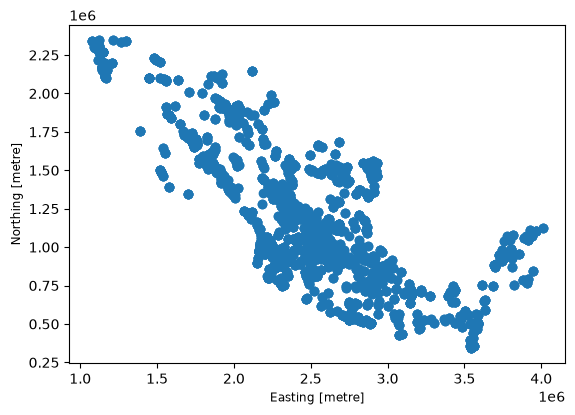

In [4]:
agro1=file1[file1['VEGETACIÓN'].isin([col for col in file1['VEGETACIÓN'].unique() if col.startswith("AGRI")])]
agro1.plot()

In [5]:
file21 = gpd.read_file(datapaths['raw']['INEGI']/"794551118313_s"/ "conjunto_de_datos"/"conj_nac_inf_edaf_esc_250k_ser_III_pto.shp")


Index(['OBJECTID', 'Id_Sitio', 'Id_Hte', 'Numero_Hte', 'Limite_sup',
       'Limite_inf', 'Contra_hte', 'Forma_hor', 'HCl', 'H2O2',
       ...
       'Afloramien', 'Escurr_sup', 'Infiltra', 'Superf_sue', 'Tipo_eros',
       'Forma_eros', 'Grado_eros', 'Influe_hum', 'Fact_nociv', 'geometry'],
      dtype='str', length=115)


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

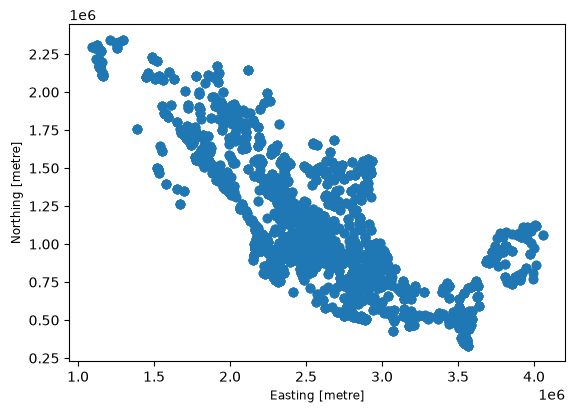

In [38]:
print(file21.columns)
file21 = file21.to_crs(epsg=6362)
agro2 = file21[file21['Cober_tier'].isin(["Agricultura", "otros tipos"])]
agro2.plot()

In [39]:
agro2.shape

(5035, 115)

In [40]:
agro1points = agro1['geometry']
agro2points = agro2['geometry']

In [80]:
import pandas as pd


agropoints = pd.concat([agro1points, agro2points]).drop_duplicates().reset_index(drop=True)
agropoints

0       POINT (2496920.996 1106347.939)
1       POINT (2349375.116 1054024.984)
2       POINT (2411642.105 1027186.557)
3       POINT (2416883.372 1063475.417)
4       POINT (2386821.517 1053934.947)
                     ...               
1984             POINT (2941640 958465)
1985             POINT (2979230 943591)
1986             POINT (3034710 900037)
1987            POINT (2958090 1009160)
1988            POINT (2927900 1095610)
Name: geometry, Length: 1989, dtype: geometry

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

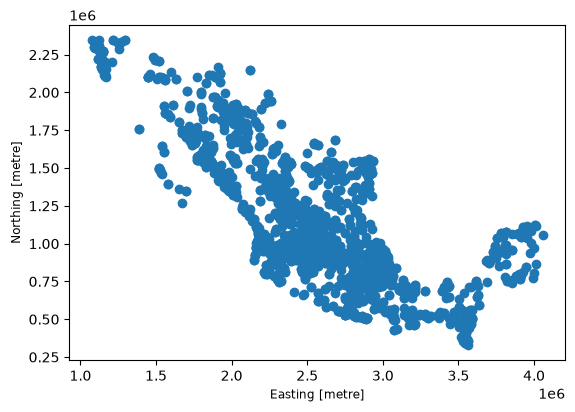

In [81]:
agropoints.plot()

In [87]:
tol = 9_000
distances = pd.DataFrame(index=agropoints, columns=agropoints)
for pi in distances.index:
    for pj in distances.columns:
        if pj!=pi and pi.distance(pj) < tol:
            distances.loc[pi, pj] = pi.distance(pj)


In [98]:
distances = distances.dropna(axis=0, how="all")
distances = distances.dropna(axis=1, how="all")
distances

geometry,POINT (2496920.996 1106347.939),POINT (2349375.116 1054024.984),POINT (2411642.105 1027186.557),POINT (2416883.372 1063475.417),POINT (2386821.517 1053934.947),POINT (2496715.653 1079482.464),POINT (2441159.288 1066947.53),POINT (2432290.707 1047306.146),POINT (2470362.79 1069869.908),POINT (2489613.73 1117039.904),...,POINT (2966890 955008),POINT (2961850 964888),POINT (2952850 992637),POINT (2960850 993025),POINT (2965770 965574),POINT (3030610 916445),POINT (2947830 979818),POINT (2958070 1003390),POINT (2979230 943591),POINT (2958090 1009160)
geometry,,,,,,,,,,,,,,,,,,,,,
POINT (2496920.996 1106347.939),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
POINT (2349375.116 1054024.984),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
POINT (2411642.105 1027186.557),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
POINT (2416883.372 1063475.417),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
POINT (2386821.517 1053934.947),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
POINT (3030610 916445),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
POINT (2947830 979818),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
POINT (2958070 1003390),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5770.034662


(633,)


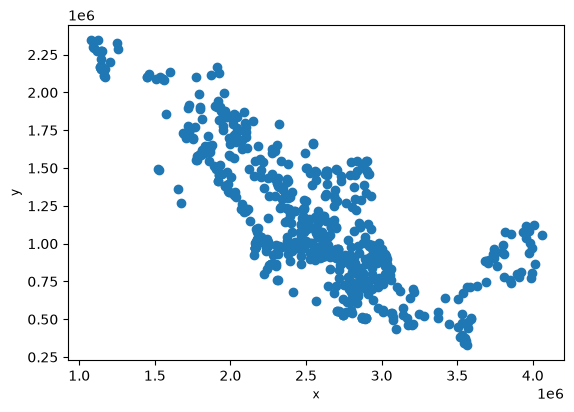

In [113]:
delete_points = []

for idx in distances.index:
    raw = distances.loc[idx]
    idy = distances.columns.to_list()[raw.argmax()]
    delete_points.append(idy)



new_agropoints = gpd.GeoSeries([ag for ag in agropoints if not ag in delete_points])
new_agropoints.plot()
print(new_agropoints.shape)

(1989,)


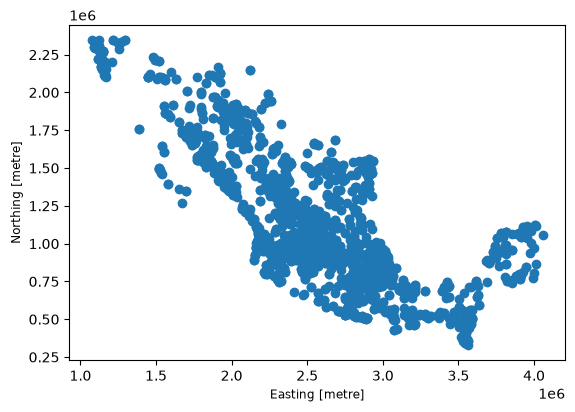

In [111]:
agropoints.plot()
print(agropoints.shape)

In [117]:
file3 = gpd.read_file(datapaths['raw']['INEGI'] / "794551131916_s"/"794551131916"/"conjunto_de_datos"/"cdv_edaf_esc_250k_serie II_cont_nac.shp")
file3.shape

(75491, 26)

In [123]:
test5 = file3[['CLAVE_WRB', "geometry"]]
test5['Validacion'] = 0

In [127]:
for point in new_agropoints:
    print(point)
    for reg in test5.index:
        region = test5.loc[reg, 'geometry']
        if region.contains(point):
            test5.loc[reg, 'Validacion']+= 1
            break

POINT (2496920.996033623 1106347.9386808209)
POINT (2489456.8544406244 1150652.6623906002)
POINT (2482060.4214226524 1149709.49825824)
POINT (2479965.0773955686 1141417.4891124184)
POINT (2468966.255220928 1129183.7544720566)
POINT (2422200.303119836 1213056.5982956637)
POINT (2396053.1056827283 1185420.1951512708)
POINT (2750031.055809563 887118.233551855)
POINT (2793553.627104276 859418.4898701708)
POINT (2808391.8315160833 858340.0213335005)
POINT (2816542.804854341 856262.7960229795)
POINT (3022110.986783426 798989.2300922982)
POINT (2922775.918427724 886223.7397019842)
POINT (2581657.8137165625 1145600.5140494248)
POINT (2373581.162242017 1147347.610357808)
POINT (2253673.754859765 1313643.8080015888)
POINT (2118273.5275724065 1227087.5051666156)
POINT (1120438.0418975472 2270793.894219546)
POINT (1206629.0801730342 2201216.784435873)
POINT (1090571.3608678277 2299261.4710519826)
POINT (1096303.412951216 2294771.986770881)
POINT (2720176.000920251 911643.102586568)
POINT (2775781.

In [130]:
agro_3 = test5[test5['Validacion']>0]

<Axes: xlabel='x', ylabel='y'>

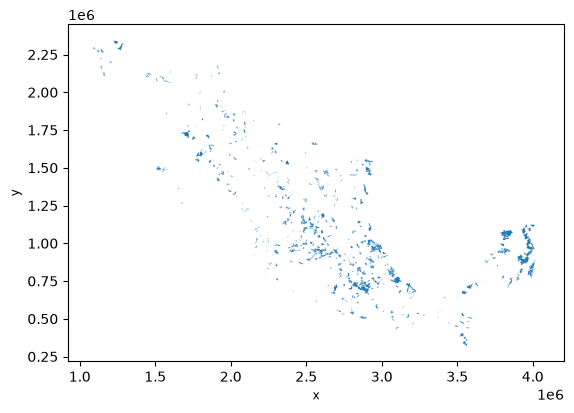

In [131]:
agro_3.plot()